# What makes pitchers similar? Arsenal versus results
**Paul Hletko · High-Dimensional Data Analysis · frozen 2017–2026 data**

**Research question.** How do pitcher groupings change when similarity is defined by pitching arsenal, pitching results, or both, and how sensitive are those groupings to method and analysis choices?

This notebook produces an empirical comparison, not a claim that MLB pitchers have a unique set of natural types. It uses pitchers only and does not predict careers. All numerical outputs below come from the supplied frozen data, not simulated data. Repeated subsampling uses real pitchers; its quantiles describe algorithmic perturbations, not population confidence intervals.

**Reading order:** data and definitions → preprocessing/PCA → cluster-count ambiguity → matched-count agreement → perturbation stability → profiles → sensitivity → measured findings and limitations. The last section computes a compact evidence summary for the proposal due November 24. Slides are due November 30 at 11:30 a.m.; the presentation is approximately five minutes on December 1 or 3.


## 1. Data provenance, units, and scope

The input is `pitcher_data.zip`, build `regular-season-coverage95-2026-11-22`, collected with **pybaseball 2.2.7**. The supplied `pitchers.ipynb` is the collection notebook; it is not rerun here. Baseball Savant provides arsenal and Statcast summaries; Baseball Reference regular-season counts provide SO, BB, and BF through pybaseball. The analysis reads `pitcher_feature_sets.json` explicitly. Neither all numeric columns nor all `res_` columns are selected.

One row summarizes a pitcher over eligible 2017–2026 seasons. A season needs at least 25 plate appearances (PA: completed batter trips to the plate). The primary sample needs at least 100 observed PA and usable measurements covering at least 95% of eligible PA. **All 17 baseline features use the same retained seasons within each pitcher.** Continuous features are PA-weighted seasonal approximations; they are not exact pooled pitch/contact averages. K% and BB% are 100 times pooled strikeouts/walks divided by pooled batters faced (BF). Small BF/PA discrepancies are audited; a season exceeding max(2 BF, 0.5% of Savant PA) is excluded from usable coverage. Pat Venditte is excluded for ambiguous duplicate arsenal records.

An **arsenal** is the mix of pitch types a pitcher throws. FF = four-seam fastball, SI = sinker, FC = cutter, SL = slider, ST = sweeper, CU = curveball, CH = changeup, FS = splitter; `other` combines the remaining types. Shares sum to one. Entropy summarizes seasonal pitch-mix diversity and is then averaged; it is not the entropy of the final averaged shares. Velocity is measured in mph, spin in rpm. Exit velocity is batted-ball speed; barrel rate measures hard contact at favorable launch angles under MLB's formal speed/angle criterion, as a percentage of batted balls. Expected weighted on-base average allowed (xwOBA) is a contact-informed offensive outcome index; lower values favor pitchers. Results here include both observed rates and expected/contact-quality summaries.

Each pitcher receives equal weight in clustering and profiles, regardless of workload. This describes the population of eligible pitchers, not the population of pitches. IDs, role, workload, WAR, xERA, and extended measurements are excluded from the baseline. Career WAR is not used to choose exemplars. Temporal averaging can obscure arsenal changes, era effects, and different precision across pitchers.


In [1]:
import os
for variable in ['OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS']:
    os.environ[variable] = '1'
import json, hashlib, platform, time, warnings
from pathlib import Path
from itertools import combinations
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy, sklearn, joblib
from IPython.display import display, Markdown
from threadpoolctl import threadpool_limits
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (adjusted_rand_score, silhouette_score,
                             calinski_harabasz_score, davies_bouldin_score)

thread_limit = threadpool_limits(limits=1)
SEED = 20261122
K_RANGE = list(range(2, 13))
DETAIL_K = 4                    # descriptive resolution, not a discovered optimum
STABILITY_K = [2, 4, 6]
N_STABILITY = 20
DATA = Path(os.environ.get('PITCHER_DATA_DIR', 'data/pitcher_data'))
if not DATA.exists():
    import zipfile
    candidates = [Path('pitcher_data.zip'), Path('../pitcher_data.zip')]
    archive = next((p for p in candidates if p.exists()), None)
    if archive is None:
        raise FileNotFoundError('Extract pitcher_data.zip into data/ or set PITCHER_DATA_DIR.')
    with zipfile.ZipFile(archive) as z:
        # Extract only the named dataset tree, never arbitrary archive paths.
        for item in z.infolist():
            parts = Path(item.filename).parts
            if parts and parts[0] == 'pitcher_data' and '..' not in parts:
                z.extract(item, 'data')
OUT, FIG = Path('outputs'), Path('figures')
OUT.mkdir(exist_ok=True); FIG.mkdir(exist_ok=True)
sns.set_theme(style='whitegrid', context='notebook', palette='colorblind')
pd.set_option('display.max_columns', 24)
pd.set_option('display.width', 160)

def savefig(name):
    plt.gcf().savefig(FIG / f'{name}.png', dpi=180, bbox_inches='tight')
    plt.show()

def table(df, name):
    df.to_csv(OUT / f'{name}.csv', index=False)
    display(df.round(4))

config = json.loads((DATA / 'pitcher_feature_sets.json').read_text())
source_manifest = json.loads((DATA / 'run_manifest.json').read_text())
FEATURE_SETS = config['baseline']
ARSENAL, RESULTS, COMBINED = [FEATURE_SETS[x] for x in ['arsenal', 'results', 'combined']]
USAGE = [c for c in ARSENAL if c.startswith('usage_')]
assert [len(ARSENAL), len(RESULTS), len(COMBINED)] == [12, 5, 17]
assert COMBINED == ARSENAL + RESULTS
df = pd.read_csv(DATA / config['baseline_input']).sort_values('mlbam_id').reset_index(drop=True)
strict = pd.read_csv(DATA / config['strict_input']).sort_values('mlbam_id').reset_index(drop=True)
extended = pd.read_csv(DATA / config['extended_input']).sort_values('mlbam_id').reset_index(drop=True)
seasons = pd.read_csv(DATA / 'pitcher_statcast_seasons.csv')
assert (len(df), len(strict), len(extended)) == (1305, 1182, 1272)
assert df.mlbam_id.is_unique and strict.mlbam_id.is_unique and extended.mlbam_id.is_unique
assert np.isfinite(df[COMBINED].to_numpy(float)).all()
assert np.allclose(df[USAGE].sum(axis=1), 1, atol=1e-8)
assert df.analysis_PA_total.ge(100).all() and df.coverage_PA_fraction.ge(.95).all()
assert seasons.pa.ge(25).all() and source_manifest['validation_passed']
validation = pd.read_csv(DATA / 'audit/final_validation.csv')
collection = pd.read_csv(DATA / 'audit/collection_log.csv')
assert validation.passed.eq(True).all() and collection.status.eq('ok').all()
for name in ['Zack Wheeler', 'Max Scherzer', 'Aaron Nola', 'Gerrit Cole',
             'Jacob deGrom', 'Chris Sale', 'Justin Verlander']:
    assert df.name.eq(name).any(), name
print('Frozen build:', source_manifest['build_tag'])
print('Feature lists:', json.dumps(FEATURE_SETS, indent=2))
print(f'Primary n={len(df)}; strict n={len(strict)}; extended n={len(extended)}')
print(f'Mean retained PA coverage: {df.coverage_PA_fraction.mean():.4%}')
print(f'Collection: {len(collection)} successful requests; validation: {len(validation)} passed checks')
table(pd.read_csv(DATA / 'audit/coverage_threshold_sensitivity.csv'), 'source_coverage_counts')
display(pd.read_csv(DATA / 'feature_dictionary.csv').query('baseline == True'))


Frozen build: regular-season-coverage95-2026-11-22
Feature lists: {
  "arsenal": [
    "usage_FF",
    "usage_SI",
    "usage_FC",
    "usage_SL",
    "usage_ST",
    "usage_CU",
    "usage_CH",
    "usage_FS",
    "usage_other",
    "arsenal_entropy",
    "velo_avg",
    "spin_avg"
  ],
  "results": [
    "res_k_percent",
    "res_bb_percent",
    "res_est_woba",
    "res_avg_hit_speed",
    "res_brl_percent"
  ],
  "combined": [
    "usage_FF",
    "usage_SI",
    "usage_FC",
    "usage_SL",
    "usage_ST",
    "usage_CU",
    "usage_CH",
    "usage_FS",
    "usage_other",
    "arsenal_entropy",
    "velo_avg",
    "spin_avg",
    "res_k_percent",
    "res_bb_percent",
    "res_est_woba",
    "res_avg_hit_speed",
    "res_brl_percent"
  ]
}
Primary n=1305; strict n=1182; extended n=1272
Mean retained PA coverage: 99.7292%
Collection: 152 successful requests; validation: 17 passed checks


,minimum_coverage,pitchers,median_eligible_seasons
0,0.90,1410,3.0
1,0.95,1305,3.0
2,1.00,1182,3.0


,feature,meaning,unit,aggregation,baseline
0,usage_FF,Mean seasonal share of pitches of this type; o...,fraction,PA-weighted seasonal share,True
1,usage_SI,Mean seasonal share of pitches of this type; o...,fraction,PA-weighted seasonal share,True
2,usage_FC,Mean seasonal share of pitches of this type; o...,fraction,PA-weighted seasonal share,True
3,usage_SL,Mean seasonal share of pitches of this type; o...,fraction,PA-weighted seasonal share,True
4,usage_ST,Mean seasonal share of pitches of this type; o...,fraction,PA-weighted seasonal share,True
5,usage_CU,Mean seasonal share of pitches of this type; o...,fraction,PA-weighted seasonal share,True
6,usage_CH,Mean seasonal share of pitches of this type; o...,fraction,PA-weighted seasonal share,True
7,usage_FS,Mean seasonal share of pitches of this type; o...,fraction,PA-weighted seasonal share,True
8,usage_other,Mean seasonal share of pitches of this type; o...,fraction,PA-weighted seasonal share,True
9,arsenal_entropy,Mean seasonal Shannon entropy of full pitch mix,nats,PA-weighted over shared usable seasons; PA cov...,True


## 2. Preprocessing and PCA

Baseline: retain the exact complete feature lists, apply **no imputation, clipping, automatic logarithms, or data-driven feature deletion**, and standardize each feature across pitchers (mean zero, population variance one). PCA retains the smallest number of components explaining at least 90% of total standardized variance; scores are **not whitened**. The same pitchers are used in all three representations. PCA is fit separately by representation.

Squared Euclidean distance in the baseline combined space adds 12 standardized arsenal contributions and 5 results contributions: arsenal has 12/17 ≈ 71% of total variance before PCA. Equal block weighting later scales each standardized arsenal feature by 1/√12 and each results feature by 1/√5. This equalizes total pre-PCA block variance, not independent information. Correlated outcome features and composition constraints still matter. Unit-variance scaling can amplify rare pitch types; a square-root-share sensitivity checks one alternative, not a definitive compositional analysis. Zero shares are observed absences, so no log-ratio pseudocount is imposed.

PCA loadings below are eigenvector coefficients, not correlations. Their signs are arbitrary. Two-dimensional projections display only part of the geometry and do not validate clusters.


arsenal top coefficients:
PC1 {'usage_FF': 0.485, 'arsenal_entropy': -0.407, 'usage_SL': 0.4, 'usage_SI': -0.368}
PC2 {'usage_SI': 0.553, 'usage_CU': -0.416, 'usage_FF': -0.402, 'usage_SL': 0.393}
PC3 {'spin_avg': 0.563, 'usage_CH': -0.502, 'usage_ST': 0.384, 'usage_FC': 0.317}
results top coefficients:
PC1 {'res_est_woba': 0.611, 'res_avg_hit_speed': 0.475, 'res_brl_percent': 0.46, 'res_k_percent': -0.434}
PC2 {'res_k_percent': 0.685, 'res_brl_percent': 0.464, 'res_avg_hit_speed': 0.379, 'res_bb_percent': 0.371}
PC3 {'res_bb_percent': 0.901, 'res_brl_percent': -0.277, 'res_est_woba': 0.224, 'res_avg_hit_speed': -0.215}
combined top coefficients:
PC1 {'res_k_percent': 0.458, 'arsenal_entropy': -0.361, 'res_est_woba': -0.356, 'velo_avg': 0.329}
PC2 {'res_brl_percent': 0.478, 'res_avg_hit_speed': 0.445, 'usage_FF': 0.419, 'res_est_woba': 0.396}
PC3 {'usage_SL': 0.458, 'usage_FC': -0.411, 'spin_avg': -0.359, 'usage_CU': -0.349}


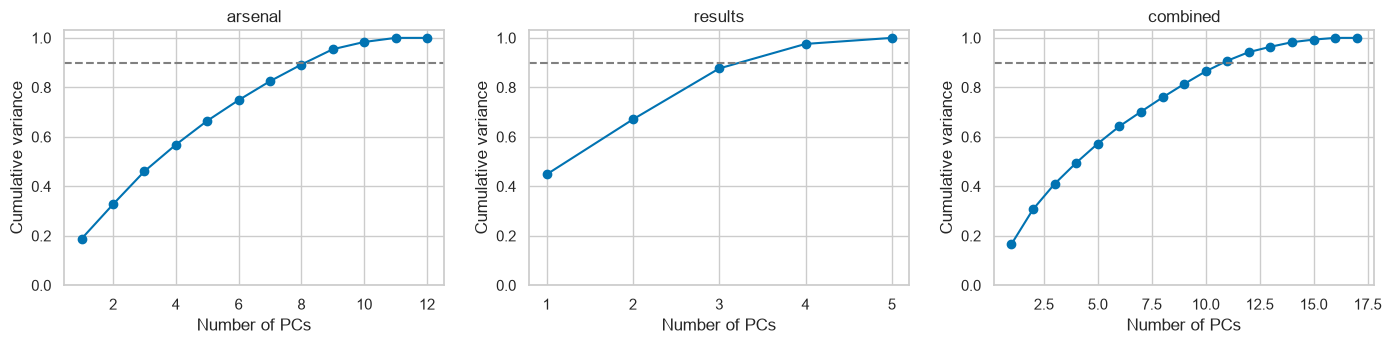

,representation,features,PCs,retained_variance,first_two_variance
0,arsenal,12,9,0.9541,0.3272
1,results,5,4,0.9756,0.6705
2,combined,17,11,0.9076,0.3070


In [2]:
def representation(frame, columns, variance=.90, arsenal_fraction=None, sqrt_usage=False):
    X = frame[columns].to_numpy(float).copy()
    assert np.isfinite(X).all(), 'No implicit missing-data handling is allowed'
    if sqrt_usage:
        for j, c in enumerate(columns):
            if c in USAGE:
                X[:, j] = np.sqrt(X[:, j])
    scaler = StandardScaler().fit(X)
    scaled = scaler.transform(X)
    weights = np.ones(len(columns))
    if arsenal_fraction is not None:
        assert set(ARSENAL + RESULTS).issubset(columns)
        weights = np.array([np.sqrt(arsenal_fraction / len(ARSENAL)) if c in ARSENAL
                            else np.sqrt((1-arsenal_fraction) / len(RESULTS)) for c in columns])
    weighted = scaled * weights
    pca = None if variance is None else PCA(n_components=variance, svd_solver='full').fit(weighted)
    Z = weighted if pca is None else pca.transform(weighted)
    return dict(Z=Z, scaler=scaler, pca=pca, columns=columns, weights=weights,
                sqrt_usage=sqrt_usage, variance=variance, arsenal_fraction=arsenal_fraction)

def transform(rep, frame):
    X = frame[rep['columns']].to_numpy(float).copy()
    if rep['sqrt_usage']:
        for j,c in enumerate(rep['columns']):
            if c in USAGE:
                X[:, j] = np.sqrt(X[:, j])
    X = rep['scaler'].transform(X) * rep['weights']
    return X if rep['pca'] is None else rep['pca'].transform(X)

reps = {name: representation(df, cols) for name,cols in FEATURE_SETS.items()}
Zs = {name: rep['Z'] for name,rep in reps.items()}  # never reused for t-SNE
pca_rows = []
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
for ax, (name, cols) in zip(axes, FEATURE_SETS.items()):
    rep = reps[name]
    full = PCA(svd_solver='full').fit(StandardScaler().fit_transform(df[cols]))
    cumulative = np.cumsum(full.explained_variance_ratio_)
    ax.plot(np.arange(1, len(cols)+1), cumulative, 'o-')
    ax.axhline(.90, ls='--', color='gray')
    ax.set(title=name, xlabel='Number of PCs', ylabel='Cumulative variance', ylim=(0, 1.03))
    pca_rows.append(dict(representation=name, features=len(cols), PCs=rep['Z'].shape[1],
                         retained_variance=rep['pca'].explained_variance_ratio_.sum(),
                         first_two_variance=full.explained_variance_ratio_[:2].sum()))
    loadings = pd.DataFrame(rep['pca'].components_.T, index=cols,
                            columns=[f'PC{i+1}' for i in range(rep['Z'].shape[1])])
    loadings.rename_axis('feature').reset_index().to_csv(OUT / f'loadings_{name}.csv', index=False)
    print(name, 'top coefficients:')
    for pc in loadings.columns[:3]:
        print(pc, loadings[pc].reindex(loadings[pc].abs().sort_values(ascending=False).index).head(4).round(3).to_dict())
plt.tight_layout(); savefig('01_pca_variance')
table(pd.DataFrame(pca_rows), 'pca_summary')


## 3. Cluster-count ambiguity and fitted models

K-means minimizes within-cluster squared distance and favors compact partitions. We use k-means++ initialization, 30 starts, and a fixed seed. GMMs estimate mixtures of Gaussian densities with **full component covariances**, 20 starts, at most 500 EM iterations, and covariance regularization 10⁻⁴. Hard labels are maximum-posterior assignments. Convergence, component weights, and minimum hard-cluster sizes are recorded. A high posterior is conditional on the fitted model; it is not proof of a true type.

We sweep k=2–12 for both methods, plus k=1 for GMM BIC. Silhouette and Calinski–Harabasz favor higher scores; Davies–Bouldin and BIC favor lower scores. Silhouette uses all pitchers. Scores are descriptive and in-sample. **BIC values are compared only within a representation and fixed preprocessing/dimension**, not across spaces. BIC selects a density approximation, not necessarily a baseball taxonomy. An endpoint optimum means the tested range does not locate an interior optimum.

No single score settles k. We report the silhouette-favored k-means partition and BIC-favored GMM partition as diagnostic selections, then compare every matched k and use **k=4 as a fixed descriptive resolution** for profiles. This avoids choosing a count because it maximizes the desired disagreement. Minimum sizes reveal when a score rewards a small specialist group.


Completed count sweep: arsenal
Completed count sweep: results
Completed count sweep: combined


,representation,method,criterion,k,score,min_cluster_n,boundary
0,arsenal,kmeans,silhouette,8,0.1916,10,False
1,arsenal,gmm,bic,9,17698.4823,11,False
2,results,kmeans,silhouette,2,0.2478,616,True
3,results,gmm,bic,2,15129.6332,376,False
4,combined,kmeans,silhouette,6,0.1407,10,False
5,combined,gmm,bic,6,32281.1149,37,False


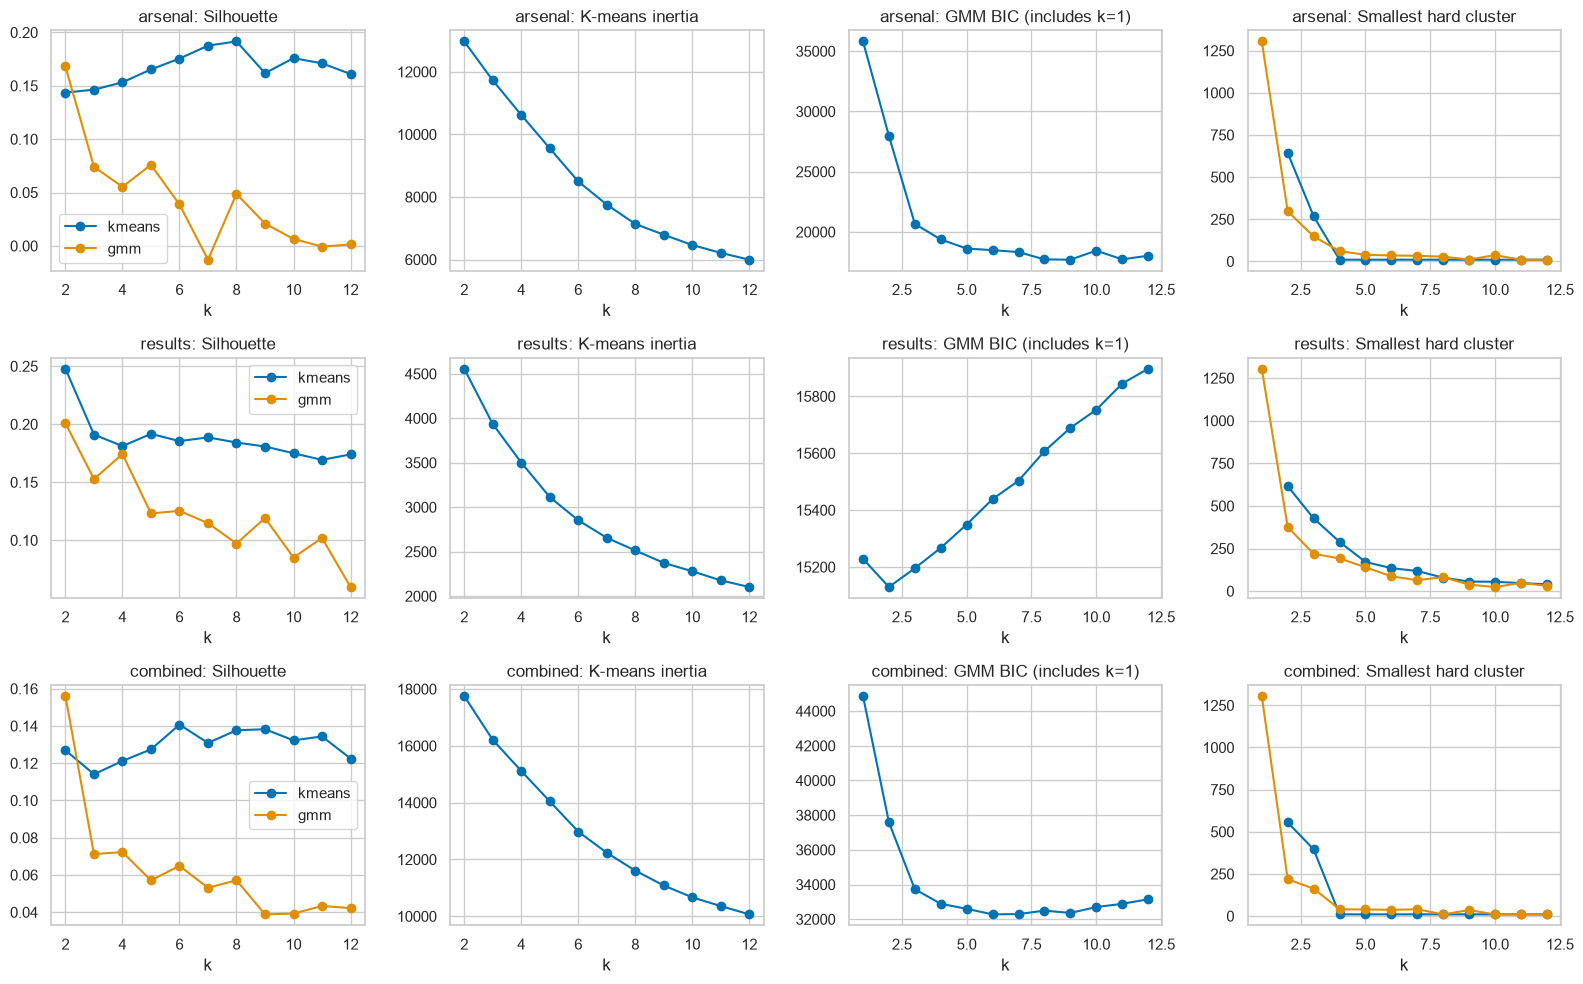

In [3]:
fit_records = []
def fit_model(Z, method, k, seed=SEED, quick=False):
    if method == 'kmeans':
        model = KMeans(n_clusters=k, n_init=10 if quick else 30,
                       max_iter=500, random_state=seed).fit(Z)
        converged = model.n_iter_ < model.max_iter
    else:
        model = GaussianMixture(n_components=k, covariance_type='full',
            n_init=5 if quick else 20, max_iter=500, reg_covar=1e-4,
            random_state=seed).fit(Z)
        converged = model.converged_
    fit_records.append(dict(method=method, k=int(k), n=len(Z), dimensions=Z.shape[1],
                            seed=int(seed), starts=int(model.n_init), converged=bool(converged), iterations=int(model.n_iter_)))
    return model

models, labels, sweep_rows = {}, {}, []
for name, Z in Zs.items():
    for method in ['kmeans', 'gmm']:
        for k in ([1]+K_RANGE if method=='gmm' else K_RANGE):
            model = fit_model(Z, method, k)
            lab = model.predict(Z)
            models[name,method,k], labels[name,method,k] = model,lab
            counts = np.bincount(lab, minlength=k)
            distinct = len(np.unique(lab))
            row = dict(representation=name, method=method, k=k,
                silhouette=silhouette_score(Z,lab) if 1<distinct<len(Z) else np.nan,
                calinski_harabasz=calinski_harabasz_score(Z,lab) if distinct>1 else np.nan,
                davies_bouldin=davies_bouldin_score(Z,lab) if distinct>1 else np.nan,
                min_cluster_n=int(counts.min()), max_cluster_n=int(counts.max()),
                hard_clusters=distinct, converged=fit_records[-1]['converged'])
            row['inertia'] = model.inertia_ if method=='kmeans' else np.nan
            row['bic'] = model.bic(Z) if method=='gmm' else np.nan
            row['min_mixture_weight'] = model.weights_.min() if method=='gmm' else np.nan
            sweep_rows.append(row)
    print('Completed count sweep:', name, flush=True)
sweep = pd.DataFrame(sweep_rows)
sweep.to_csv(OUT/'cluster_count_sweep.csv', index=False)
selections = []
for name in FEATURE_SETS:
    for method,metric in [('kmeans','silhouette'), ('gmm','bic')]:
        tab = sweep.query('representation == @name and method == @method')
        best = tab.loc[tab[metric].idxmax() if method=='kmeans' else tab[metric].idxmin()]
        selections.append(dict(representation=name, method=method, criterion=metric,
            k=int(best.k), score=best[metric], min_cluster_n=int(best.min_cluster_n),
            boundary=bool(best.k in [tab.k.min(),tab.k.max()])))
selection = pd.DataFrame(selections)
table(selection, 'diagnostic_selections')
fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for row,name in enumerate(FEATURE_SETS):
    for method in ['kmeans','gmm']:
        t = sweep.query('representation == @name and method == @method')
        axes[row,0].plot(t.k,t.silhouette,'o-',label=method)
        axes[row,3].plot(t.k,t.min_cluster_n,'o-',label=method)
    t=sweep.query('representation == @name and method == "kmeans"')
    axes[row,1].plot(t.k,t.inertia,'o-')
    t=sweep.query('representation == @name and method == "gmm"')
    axes[row,2].plot(t.k,t.bic,'o-')
    for j,title in enumerate(['Silhouette','K-means inertia','GMM BIC (includes k=1)','Smallest hard cluster']):
        axes[row,j].set(title=f'{name}: {title}',xlabel='k')
    axes[row,0].legend()
plt.tight_layout();savefig('02_cluster_count_diagnostics')


## 4. Representation agreement versus method agreement

The adjusted Rand index (ARI) compares whether pairs of pitchers are grouped together, adjusts for chance under the standard fixed-partition null, and is invariant to cluster label names. ARI=1 means identical partitions; around zero indicates chance-level agreement under that null, and negative values are possible. It does not assess correctness or independence of the underlying baseball quantities.

The main comparison holds k fixed. We compare arsenal versus results, each versus combined, and k-means versus GMM within each representation. Different-k, criterion-selected partitions are provided separately. At a fixed k we also calculate mean method agreement minus mean arsenal/results agreement; a positive gap favors greater sensitivity to representation for these configurations. This is a descriptive contrast, not a significance test or universal ranking of analytical choices.


,k,mean_method_ARI,mean_arsenal_results_ARI,gap
0,2,0.0233,0.0001,0.0232
1,3,0.1210,0.0204,0.1006
2,4,0.1175,0.0192,0.0982
3,5,0.2384,0.0133,0.2251
4,6,0.2449,0.0122,0.2327
5,7,0.2511,0.0113,0.2398
6,8,0.2128,0.0164,0.1964
7,9,0.2284,0.0145,0.2139
8,10,0.2341,0.0125,0.2216
9,11,0.2373,0.0139,0.2234


,k,comparison,method,pair,ari
0,4,representation,kmeans,arsenal vs results,0.0370
1,4,representation,kmeans,arsenal vs combined,0.3639
2,4,representation,kmeans,results vs combined,0.1844
3,4,representation,gmm,arsenal vs results,0.0015
4,4,representation,gmm,arsenal vs combined,0.5134
5,4,representation,gmm,results vs combined,-0.0045
6,4,method,kmeans vs gmm,arsenal,0.0778
7,4,method,kmeans vs gmm,results,0.2325
8,4,method,kmeans vs gmm,combined,0.0421


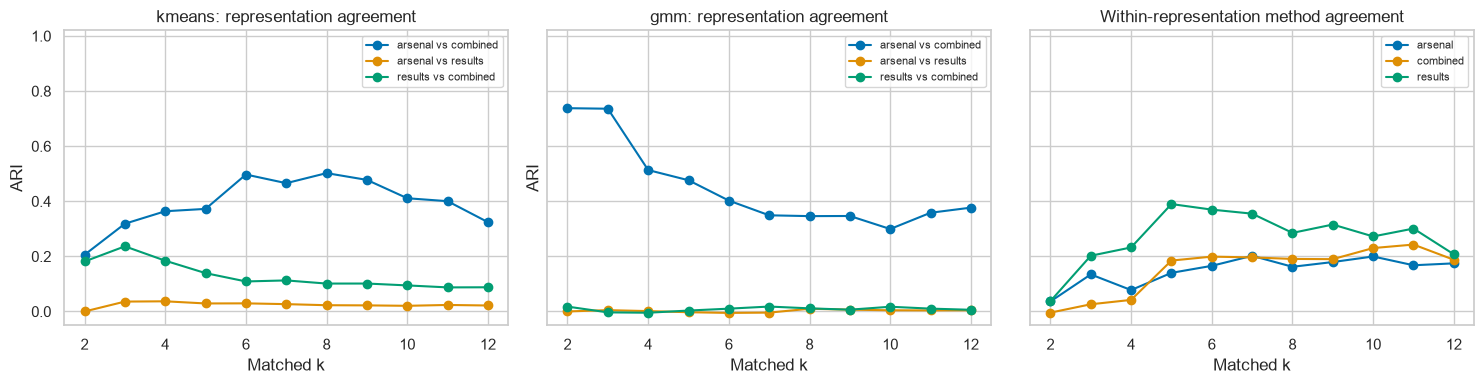

,arsenal/kmeans/k=8,arsenal/gmm/k=9,results/kmeans/k=2,results/gmm/k=2,combined/kmeans/k=6,combined/gmm/k=6
arsenal/kmeans/k=8,1.000,0.186,0.004,-0.000,0.360,0.219
arsenal/gmm/k=9,0.186,1.000,0.002,0.001,0.145,0.327
results/kmeans/k=2,0.004,0.002,1.000,0.038,0.146,-0.001
results/gmm/k=2,-0.000,0.001,0.038,1.000,-0.009,0.003
combined/kmeans/k=6,0.360,0.145,0.146,-0.009,1.000,0.199
combined/gmm/k=6,0.219,0.327,-0.001,0.003,0.199,1.000


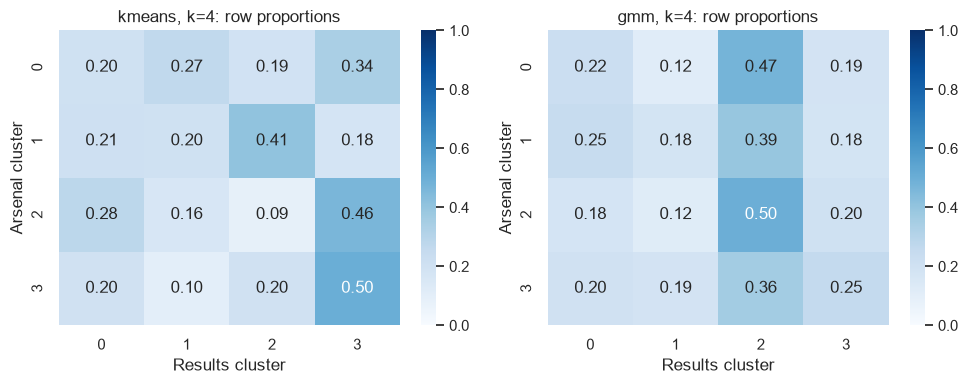

In [4]:
agreement_rows=[]
for k in K_RANGE:
    for method in ['kmeans','gmm']:
        for a,b in combinations(FEATURE_SETS,2):
            agreement_rows.append(dict(k=k, comparison='representation', method=method,
                pair=f'{a} vs {b}', ari=adjusted_rand_score(labels[a,method,k],labels[b,method,k])))
    for name in FEATURE_SETS:
        agreement_rows.append(dict(k=k, comparison='method',method='kmeans vs gmm',pair=name,
            ari=adjusted_rand_score(labels[name,'kmeans',k],labels[name,'gmm',k])))
agreement=pd.DataFrame(agreement_rows)
agreement.to_csv(OUT/'matched_k_agreement.csv',index=False)
gap_rows=[]
for k in K_RANGE:
    x=agreement.query('k == @k')
    within=x.query('comparison == "method"').ari.mean()
    across=x.query('pair == "arsenal vs results"').ari.mean()
    gap_rows.append(dict(k=k,mean_method_ARI=within,mean_arsenal_results_ARI=across,gap=within-across))
gaps=pd.DataFrame(gap_rows)
table(gaps,'representation_method_gap')
table(agreement.query('k == @DETAIL_K').reset_index(drop=True),'agreement_k4')
fig,axes=plt.subplots(1,3,figsize=(15,4),sharey=True)
for ax,method in zip(axes[:2],['kmeans','gmm']):
    t=agreement.query('comparison == "representation" and method == @method')
    for pair,g in t.groupby('pair'):
        ax.plot(g.k,g.ari,'o-',label=pair)
    ax.set(title=f'{method}: representation agreement',xlabel='Matched k',ylabel='ARI',ylim=(-.05,1.02))
    ax.legend(fontsize=8)
for pair,g in agreement.query('comparison == "method"').groupby('pair'):
    axes[2].plot(g.k,g.ari,'o-',label=pair)
axes[2].set(title='Within-representation method agreement',xlabel='Matched k');axes[2].legend(fontsize=8)
plt.tight_layout();savefig('03_matched_k_agreement')

selected_labels={f'{r.representation}/{r.method}/k={r.k}':labels[r.representation,r.method,r.k]
                 for r in selection.itertuples()}
selected_ari=pd.DataFrame({a:{b:adjusted_rand_score(x,y) for b,y in selected_labels.items()}
                           for a,x in selected_labels.items()})
selected_ari.to_csv(OUT/'criterion_selected_ari.csv')
display(selected_ari.round(3))
fig,axes=plt.subplots(1,2,figsize=(10,4))
for ax,method in zip(axes,['kmeans','gmm']):
    cross=pd.crosstab(labels['arsenal',method,DETAIL_K], labels['results',method,DETAIL_K],normalize='index')
    sns.heatmap(cross,annot=True,fmt='.2f',vmin=0,vmax=1,cmap='Blues',ax=ax)
    ax.set(title=f'{method}, k=4: row proportions',xlabel='Results cluster',ylabel='Arsenal cluster')
    cross.to_csv(OUT/f'crosswalk_k4_{method}.csv')
plt.tight_layout();savefig('04_arsenal_results_crosswalk')


## 5. Stability: refit the entire pipeline

For each of k=2,4,6, draw **20 pairs of independent 80% subsamples without replacement**. Refit standardization, PCA, and clustering separately inside each subsample; compare predicted labels only on the pitchers common to the two subsamples. This measures pipeline perturbation stability on overlapping training data, not out-of-sample prediction or biological truth. Identical subsample pairs are used across representations and methods. Fits use 10 starts for k-means and 5 for GMM to control cost; the full-data sweep uses 30 and 20. The lower optimization budget is a limitation, and fixed-data initialization sensitivity is checked separately with the same 30/20-start budgets as the baseline.

Report the mean, median, and empirical 10th/90th percentiles, with individual replicate scores exported. These are **not confidence intervals**: the samples overlap and the source population is fixed. High stability can occur when an algorithm repeatedly cuts a continuum. The optional t-SNE section is display only and supplies no validation evidence.


Completed full-pipeline stability: arsenal
Completed full-pipeline stability: results
Completed full-pipeline stability: combined


,representation,method,k,mean,median,p10,p90,minimum
0,arsenal,gmm,2,0.3066,0.0401,0.0264,0.8254,0.0170
1,arsenal,gmm,4,0.7396,0.7159,0.5826,0.9574,0.3170
2,arsenal,gmm,6,0.7623,0.7876,0.6693,0.8404,0.6080
3,arsenal,kmeans,2,0.8317,0.8610,0.6473,0.9107,0.5656
4,arsenal,kmeans,4,0.6072,0.6180,0.4145,0.8125,0.3357
5,arsenal,kmeans,6,0.7646,0.7969,0.5782,0.8875,0.5082
6,combined,gmm,2,0.3925,0.3055,0.0445,0.8629,0.0165
7,combined,gmm,4,0.6926,0.6993,0.5378,0.8377,0.4991
8,combined,gmm,6,0.4690,0.4306,0.3658,0.6383,0.2706
9,combined,kmeans,2,0.8014,0.8108,0.6908,0.9116,0.6023


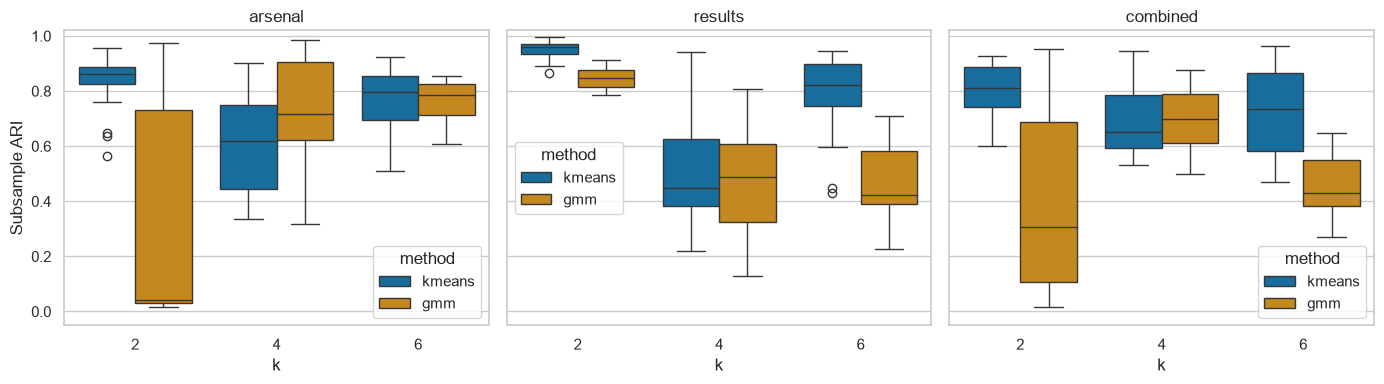

,representation,method,mean,min,max
0,arsenal,gmm,0.9599,0.9359,1.0000
1,arsenal,kmeans,0.8233,0.4891,0.9523
2,combined,gmm,0.9575,0.8918,0.9983
3,combined,kmeans,0.9204,0.8417,0.9620
4,results,gmm,0.7562,0.5555,0.9639
5,results,kmeans,0.9083,0.5131,0.9892


In [5]:
rng=np.random.default_rng(SEED)
sample_pairs=[(rng.choice(len(df),int(.8*len(df)),replace=False),
               rng.choice(len(df),int(.8*len(df)),replace=False)) for _ in range(N_STABILITY)]
stability_rows=[]
for name,cols in FEATURE_SETS.items():
    for repeat,(i1,i2) in enumerate(sample_pairs):
        common=np.intersect1d(i1,i2)
        r1=representation(df.iloc[i1],cols);r2=representation(df.iloc[i2],cols)
        common1=transform(r1,df.iloc[common]);common2=transform(r2,df.iloc[common])
        for method in ['kmeans','gmm']:
            for k in STABILITY_K:
                seed=SEED+repeat+100*k
                m1=fit_model(r1['Z'],method,k,seed,quick=True)
                m2=fit_model(r2['Z'],method,k,seed+10000,quick=True)
                stability_rows.append(dict(representation=name,method=method,k=k,repeat=repeat,
                    common_n=len(common),ari=adjusted_rand_score(m1.predict(common1),m2.predict(common2))))
    print('Completed full-pipeline stability:',name,flush=True)
stability=pd.DataFrame(stability_rows)
stability.to_csv(OUT/'stability_replicates.csv',index=False)
stability_summary=stability.groupby(['representation','method','k']).ari.agg(
    mean='mean',median='median',p10=lambda x:x.quantile(.1),p90=lambda x:x.quantile(.9),minimum='min').reset_index()
table(stability_summary,'stability_summary')
fig,axes=plt.subplots(1,3,figsize=(14,4),sharey=True)
for ax,name in zip(axes,FEATURE_SETS):
    sns.boxplot(data=stability.query('representation == @name'),x='k',y='ari',hue='method',ax=ax)
    ax.set(title=name,ylabel='Subsample ARI',ylim=(-.05,1.02))
plt.tight_layout();savefig('05_pipeline_stability')

initialization_rows=[]
for name,Z in Zs.items():
    for method in ['kmeans','gmm']:
        for repeat in range(10):
            m=fit_model(Z,method,DETAIL_K,SEED+50000+repeat)
            baseline=models[name,method,DETAIL_K]
            objective=m.inertia_ if method=='kmeans' else m.score(Z)
            baseline_objective=baseline.inertia_ if method=='kmeans' else baseline.score(Z)
            initialization_rows.append(dict(representation=name,method=method,repeat=repeat,
                ari_to_baseline=adjusted_rand_score(labels[name,method,DETAIL_K],m.predict(Z)),
                objective=objective,baseline_objective=baseline_objective,
                objective_improvement=(baseline_objective-objective if method=='kmeans' else objective-baseline_objective)))
initialization=pd.DataFrame(initialization_rows)
table(initialization.groupby(['representation','method']).ari_to_baseline.agg(['mean','min','max']).reset_index(),
      'initialization_summary')
initialization.to_csv(OUT/'initialization_replicates.csv',index=False)


## 6. Operational interpretation: profiles and representative pitchers

Interpretability is defined operationally: **(1)** at least two visible original-unit feature differences, alongside standardized mean deviations; **(2)** cluster size and within-cluster spread; **(3)** actual pitchers near the fitted center; and **(4)** whether the description survives perturbations. The tables and sensitivities support these checks; they do not provide an independent expert rating. Feature contrasts used to describe a cluster are circular descriptions, not hypothesis-test discoveries.

Profiles report **unweighted pitcher means and medians in original units**, plus standard deviations; all 17 features are included even when the partition used only one block. A representative is the nearest actual member to the k-means center or, for GMM, the component mean in fitted PCA space (Euclidean distance); this is not a medoid or a star ranking. Three nearest members are exported. For GMM, posterior uncertainty and component sizes are also shown. Role/workload are descriptors only, and their registry window can differ from retained feature seasons.

The η² table is between-cluster sum of squares divided by total sum of squares for each **original feature**, then averaged within each block. This is descriptive variance accounting, including cross-block description; it is not predictive accuracy or evidence that clusters caused the outcomes. Every pitcher remains equally weighted.


,representation,method,cluster,n,representative,nearest_three,strongest_deviations,median_observed_PA,mean_GS_share
0,arsenal,kmeans,0,574,DL Hall,DL Hall; Nick Kingham; Carson Fulmer,arsenal_entropy: +0.62 SD; usage_SL: -0.55 SD;...,799.5,0.4766
1,arsenal,kmeans,1,452,Jon Gray,Jon Gray; Antonio Senzatela; Eduardo Paredes,usage_FF: +0.84 SD; usage_SI: -0.67 SD; arsena...,635.5,0.2267
2,arsenal,kmeans,2,269,Dario Agrazal,Dario Agrazal; Clayton Richard; J.C. Mej\xc3\xada,usage_SI: +1.57 SD; usage_FF: -1.27 SD; spin_a...,705.0,0.2372
3,arsenal,kmeans,3,10,Mitch Bratt,Mitch Bratt; Julio Ur\xc3\xadas; Kyle Harrison,usage_other: +10.50 SD; usage_SL: -0.74 SD; us...,1166.0,0.6772
4,arsenal,gmm,0,424,Emerson Hancock,Emerson Hancock; Anthony Kay; Brock Stewart,usage_ST: +0.96 SD; arsenal_entropy: +0.42 SD;...,824.5,0.4009
5,arsenal,gmm,1,61,Casey Mize,Casey Mize; H\xc3\xa9ctor Santiago; Sean Newcomb,usage_other: +2.23 SD; usage_FS: +2.02 SD; spi...,1006.0,0.3172
6,arsenal,gmm,2,309,Derek Law,Derek Law; Matt Strahm; Chi Chi Gonz\xc3\xa1lez,usage_FC: +0.84 SD; usage_ST: -0.46 SD; usage_...,960.0,0.4069
7,arsenal,gmm,3,511,Robbie Ray,Robbie Ray; Humberto Mej\xc3\xada; J.A. Happ,usage_FC: -0.58 SD; usage_SL: +0.54 SD; usage_...,491.0,0.2575
8,results,kmeans,0,289,Caleb Ferguson,Caleb Ferguson; Danny Coulombe; Tony Sipp,res_avg_hit_speed: -1.09 SD; res_est_woba: -0....,732.0,0.1914
9,results,kmeans,1,290,Max Castillo,Max Castillo; Roansy Contreras; Nick Tropeano,res_est_woba: +1.21 SD; res_brl_percent: +1.03...,365.5,0.3889


,representation,k,median_max_posterior,fraction_below_80pct,min_weight,min_hard_cluster
0,arsenal,4,0.9991,0.0215,0.0476,61
1,results,4,0.7115,0.6766,0.1633,192
2,combined,4,0.9982,0.0536,0.0314,40


,representation,method,block,eta_squared
0,arsenal,gmm,arsenal,0.1454
1,arsenal,gmm,results,0.0103
2,arsenal,kmeans,arsenal,0.2759
3,arsenal,kmeans,results,0.0533
4,combined,gmm,arsenal,0.1758
5,combined,gmm,results,0.0094
6,combined,kmeans,arsenal,0.2300
7,combined,kmeans,results,0.2182
8,results,gmm,arsenal,0.0236
9,results,gmm,results,0.3847


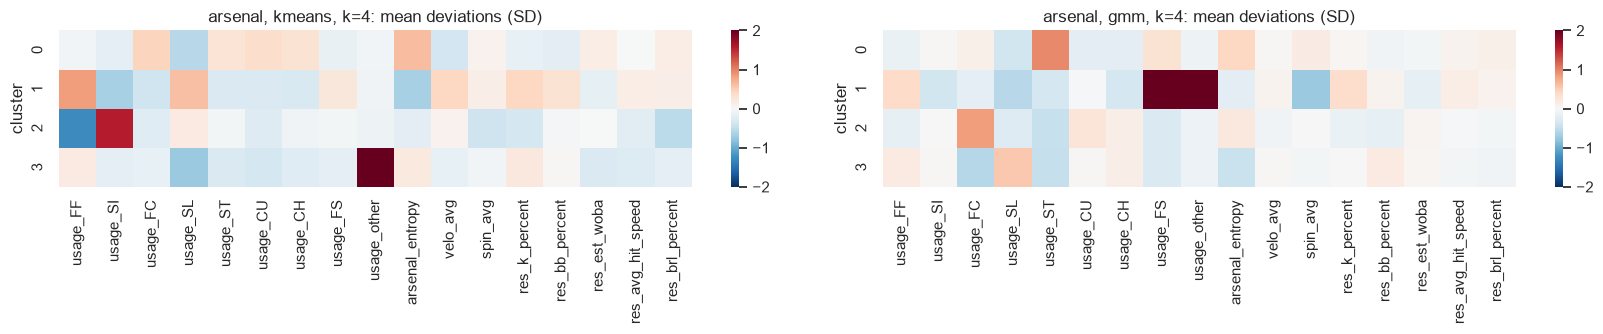

feature             arsenal_entropy  res_avg_hit_speed  res_bb_percent  res_brl_percent  res_est_woba  res_k_percent  spin_avg  usage_CH  usage_CU  usage_FC  \
method cluster n                                                                                                                                               
gmm    0       424            1.323             88.750           8.994            7.788         0.319         21.988  2276.058     0.082     0.066     0.079   
       1       61             1.163             88.848           9.398            7.727         0.316         23.532  2109.666     0.068     0.085     0.043   
       2       309            1.268             88.611           8.741            7.443         0.323         21.171  2247.498     0.116     0.113     0.160   
       3       511            1.102             88.569           9.672            7.391         0.322         21.866  2237.758     0.116     0.090     0.000   
kmeans 0       574            1.374             88.638           8.675            7.845         0.326         21.021  2263.608     0.131     0.123     0.115   
       1       452            1.046             88.849           9.966            7.803         0.316         23.795  2270.021     0.072     0.059     0.020   
       2       269            1.162             88.357           9.122            6.500         0.321         20.165  2171.077     0.094     0.061     0.037   
       3       10             1.266             88.293           9.292            7.156         0.313         22.798  2232.921     0.080     0.052     0.047   

feature             usage_FF  usage_FS  usage_SI  usage_SL  usage_ST  usage_other  velo_avg  
method cluster n                                                                             
gmm    0       424     0.322     0.037     0.167     0.112     0.135        0.000    89.133  
       1       61      0.415     0.145     0.096     0.086     0.011        0.050    89.272  
       2       309     0.314     0.000     0.165     0.130     0.001        0.000    88.840  
       3       511     0.379     0.000     0.169     0.246     0.000        0.000    89.164  
kmeans 0       574     0.335     0.010     0.128     0.087     0.070        0.001    88.044  
       1       452     0.496     0.033     0.047     0.257     0.016        0.000    90.260  
       2       269     0.119     0.016     0.438     0.195     0.040        0.000    89.335  
       3       10      0.380     0.007     0.129     0.060     0.018        0.227    88.611

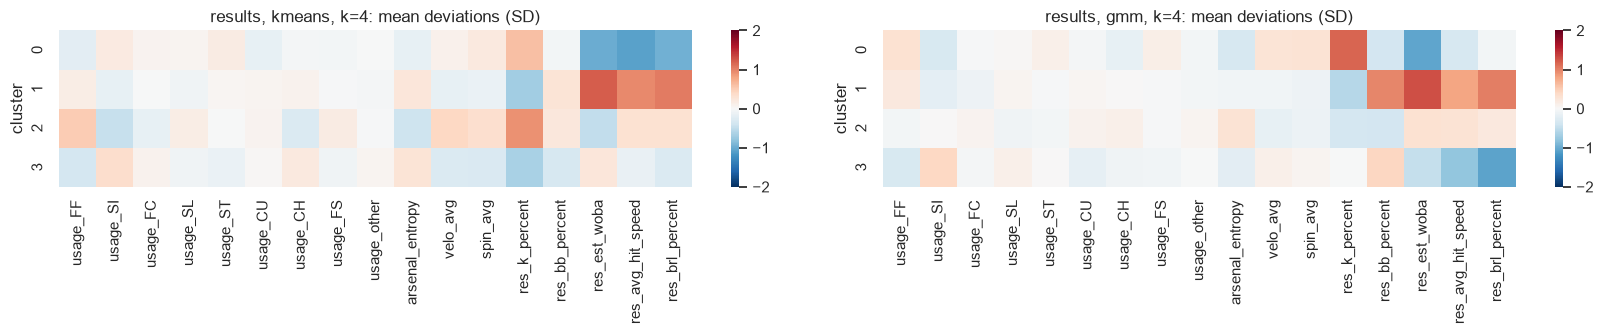

feature             arsenal_entropy  res_avg_hit_speed  res_bb_percent  res_brl_percent  res_est_woba  res_k_percent  spin_avg  usage_CH  usage_CU  usage_FC  \
method cluster n                                                                                                                                               
gmm    0       267            1.130             88.196           8.278            7.446         0.291         27.287  2299.046     0.087     0.084     0.063   
       1       192            1.199             89.701          11.716            9.547         0.358         19.160  2226.942     0.103     0.091     0.055   
       2       563            1.291             89.044           8.265            7.972         0.330         20.156  2223.946     0.114     0.097     0.073   
       3       283            1.161             87.585          10.309            5.444         0.307         21.772  2255.158     0.095     0.070     0.060   
kmeans 0       289            1.176             87.191           9.085            5.662         0.293         24.631  2282.933     0.099     0.071     0.073   
       1       290            1.278             89.935           9.934            9.570         0.356         18.537  2221.348     0.111     0.093     0.065   
       2       321            1.109             89.058           9.781            8.132         0.307         26.113  2307.226     0.075     0.094     0.047   
       3       405            1.285             88.450           8.357            6.982         0.328         18.759  2190.448     0.122     0.090     0.075   

feature             usage_FF  usage_FS  usage_SI  usage_SL  usage_ST  usage_other  velo_avg  
method cluster n                                                                             
gmm    0       267     0.402     0.027     0.109     0.170     0.056        0.001    89.835  
       1       192     0.385     0.018     0.129     0.175     0.043        0.001    88.906  
       2       563     0.336     0.018     0.166     0.155     0.040        0.003    88.625  
       3       283     0.291     0.014     0.236     0.186     0.046        0.002    89.400  
kmeans 0       289     0.309     0.016     0.195     0.175     0.060        0.002    89.386  
       1       290     0.372     0.018     0.136     0.156     0.048        0.001    88.641  
       2       321     0.437     0.029     0.084     0.189     0.044        0.002    90.246  
       3       405     0.284     0.014     0.225     0.155     0.032        0.004    88.259

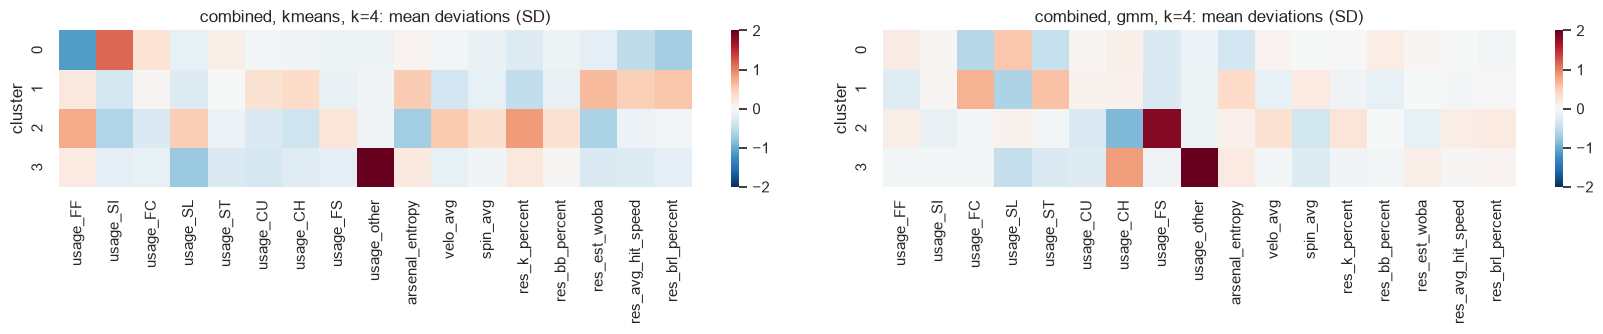

feature             arsenal_entropy  res_avg_hit_speed  res_bb_percent  res_brl_percent  res_est_woba  res_k_percent  spin_avg  usage_CH  usage_CU  usage_FC  \
method cluster n                                                                                                                                               
gmm    0       592            1.124             88.643           9.593            7.429         0.322         21.840  2243.832     0.114     0.091     0.002   
       1       498            1.313             88.590           8.795            7.561         0.321         21.395  2278.242     0.113     0.095     0.143   
       2       175            1.242             88.842           9.189            7.891         0.317         23.032  2176.663     0.017     0.059     0.060   
       3       40             1.261             88.690           9.092            7.643         0.325         21.474  2197.000     0.184     0.062     0.059   
kmeans 0       375            1.231             87.968           8.958            6.206         0.316         20.622  2222.738     0.095     0.083     0.097   
       1       516            1.343             89.280           8.841            8.620         0.339         19.538  2216.587     0.141     0.116     0.069   
       2       404            1.039             88.490           9.941            7.434         0.303         25.820  2307.164     0.062     0.057     0.032   
       3       10             1.266             88.293           9.292            7.156         0.313         22.798  2232.921     0.080     0.052     0.047   

feature             usage_FF  usage_FS  usage_SI  usage_SL  usage_ST  usage_other  velo_avg  
method cluster n                                                                             
gmm    0       592     0.376     0.000     0.169     0.246     0.002        0.000    89.222  
       1       498     0.304     0.001     0.167     0.076     0.100        0.000    88.641  
       2       175     0.371     0.134     0.140     0.180     0.040        0.000    89.906  
       3       40      0.336     0.013     0.155     0.099     0.016        0.076    88.911  
kmeans 0       375     0.147     0.013     0.364     0.144     0.057        0.000    88.926  
       1       516     0.386     0.011     0.102     0.131     0.045        0.001    88.075  
       2       404     0.481     0.035     0.059     0.240     0.034        0.001    90.525  
       3       10      0.380     0.007     0.129     0.060     0.018        0.227    88.611

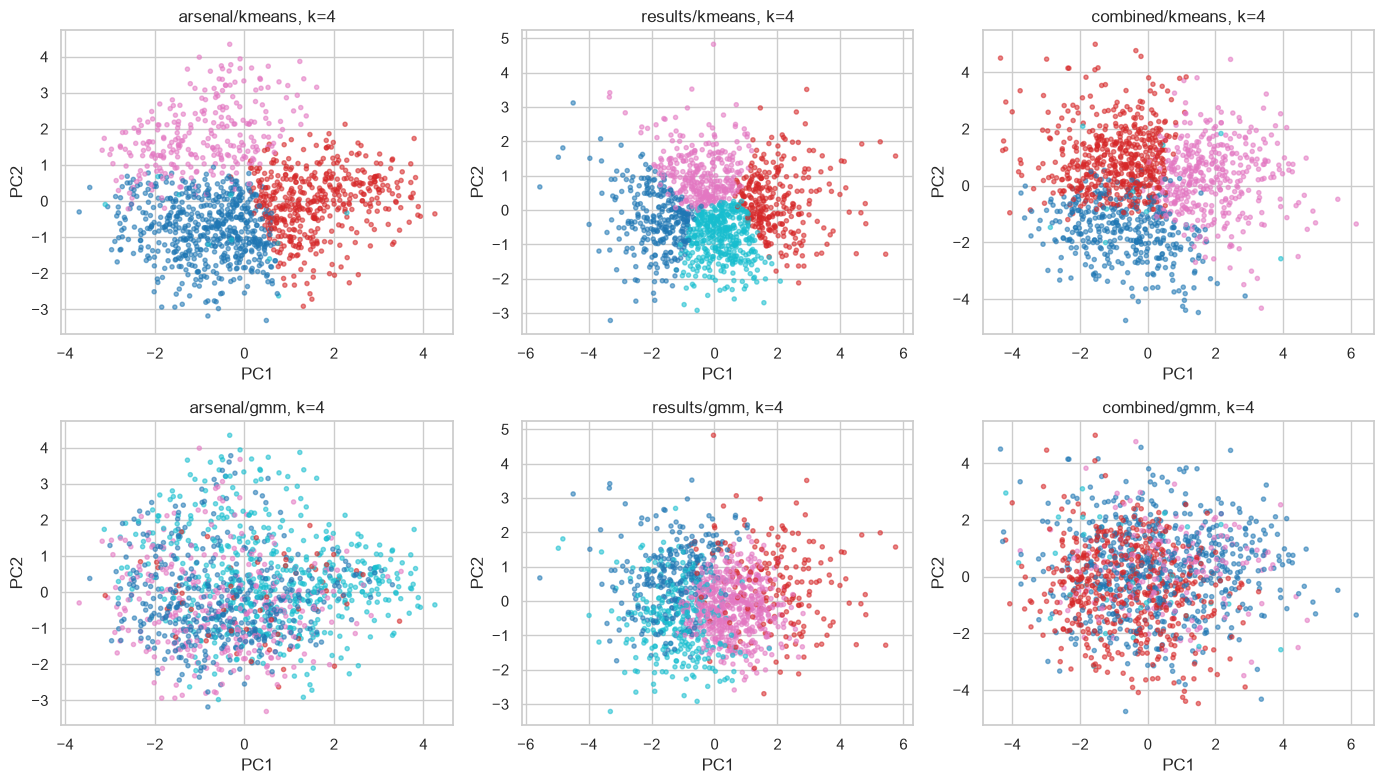

In [6]:
profile_rows=[];representative_rows=[];eta_rows=[];posterior_rows=[]
standardized_all=pd.DataFrame(StandardScaler().fit_transform(df[COMBINED]),columns=COMBINED)
for name in FEATURE_SETS:
    for method in ['kmeans','gmm']:
        lab=labels[name,method,DETAIL_K];m=models[name,method,DETAIL_K];Z=Zs[name]
        centers=m.cluster_centers_ if method=='kmeans' else m.means_
        for c in range(DETAIL_K):
            members=np.flatnonzero(lab==c)
            if not len(members):continue
            distance=np.linalg.norm(Z[members]-centers[c],axis=1)
            nearest=members[np.argsort(distance)[:3]]
            contrasts=standardized_all.iloc[members][FEATURE_SETS[name]].mean()
            top=contrasts.reindex(contrasts.abs().sort_values(ascending=False).index).head(3)
            rr=dict(representation=name,method=method,cluster=c,n=len(members),
                representative=df.iloc[nearest[0]]['name'],
                nearest_three='; '.join(df.iloc[nearest]['name'].astype(str)),
                strongest_deviations='; '.join(f'{f}: {v:+.2f} SD' for f,v in top.items()),
                median_observed_PA=df.iloc[members].analysis_PA_total.median(),
                mean_GS_share=df.iloc[members].GS_share.mean())
            representative_rows.append(rr)
            for feature in COMBINED:
                values=df.iloc[members][feature]
                profile_rows.append(dict(representation=name,method=method,cluster=c,n=len(members),
                    feature=feature,mean=values.mean(),median=values.median(),sd=values.std(),
                    standardized_mean=standardized_all.iloc[members][feature].mean()))
        for feature in COMBINED:
            overall=df[feature].mean();total=((df[feature]-overall)**2).sum()
            between=sum((lab==c).sum()*(df.loc[lab==c,feature].mean()-overall)**2
                        for c in np.unique(lab))
            eta_rows.append(dict(representation=name,method=method,feature=feature,
                block='arsenal' if feature in ARSENAL else 'results',eta_squared=between/total))
        if method=='gmm':
            p=m.predict_proba(Z);maximum=p.max(axis=1)
            posterior_rows.append(dict(representation=name,k=DETAIL_K,
                median_max_posterior=np.median(maximum),fraction_below_80pct=np.mean(maximum<.8),
                min_weight=m.weights_.min(),min_hard_cluster=np.bincount(lab,minlength=DETAIL_K).min()))
profiles=pd.DataFrame(profile_rows);representatives=pd.DataFrame(representative_rows)
profiles.to_csv(OUT/'profiles_k4_long.csv',index=False)
table(representatives,'representatives_k4')
table(pd.DataFrame(posterior_rows),'gmm_posterior_summary_k4')
eta=pd.DataFrame(eta_rows)
eta.to_csv(OUT/'variance_accounting_by_feature.csv',index=False)
table(eta.groupby(['representation','method','block']).eta_squared.mean().reset_index(),'variance_accounting_blocks')
for name in FEATURE_SETS:
    fig,axes=plt.subplots(1,2,figsize=(17,3.5))
    for ax,method in zip(axes,['kmeans','gmm']):
        p=profiles.query('representation == @name and method == @method')
        wide=p.pivot(index='cluster',columns='feature',values='standardized_mean').reindex(columns=COMBINED)
        sns.heatmap(wide,ax=ax,cmap='RdBu_r',center=0,vmin=-2,vmax=2)
        ax.set(title=f'{name}, {method}, k=4: mean deviations (SD)',xlabel='')
    plt.tight_layout();savefig(f'06_profiles_{name}')
    means=profiles.query('representation == @name').pivot(index=['method','cluster','n'],columns='feature',values='mean')
    means.to_csv(OUT/f'original_unit_means_k4_{name}.csv')
    display(means.round(3))

fig,axes=plt.subplots(2,3,figsize=(14,8))
for col,name in enumerate(FEATURE_SETS):
    for row,method in enumerate(['kmeans','gmm']):
        Z=Zs[name];ax=axes[row,col]
        ax.scatter(Z[:,0],Z[:,1],c=labels[name,method,DETAIL_K],s=9,alpha=.55,cmap='tab10')
        ax.set(title=f'{name}/{method}, k=4',xlabel='PC1',ylabel='PC2')
plt.tight_layout();savefig('07_pca_cluster_display')


## 7. Targeted sensitivity checks

All checks use **k=4 for both methods** and refit the pipeline. They address the comparison at that resolution; they do not establish robustness for every k. ARI to baseline is evaluated only on shared MLBAM IDs, with baseline labels restricted to those same pitchers. `overlap_n` is explicit. Each setting also recomputes arsenal/results agreement on its common sample and within-representation method agreement.

* Coverage: rebuild membership from the exported full feature table at 90%, 95%, and 100% using complete finite baseline features and ≥100 observed PA. Verify 95% IDs/values match primary and 100% IDs/values match the strict file. No source requests or changes to observed seasons occur. Raising coverage changes the population, not only data quality.
* PCA: retain 80%, 95%, or all standardized features (no PCA), versus baseline 90%. The all-feature GMM uses regularization despite exact usage-share closure; do not compare its BIC to reduced-dimensional BIC.
* Combined weights: arsenal fractions 0.25, 0.50, and 0.75 of pre-PCA variance. **0.50 is equal block weighting**. These alter only combined; baseline arsenal/results partitions are reused. Full-covariance GMM would be affine-equivariant without regularization/PCA; observed weighting sensitivity can therefore come from truncation, numerical regularization, and local optima.
* Share geometry: square-root usage shares before standardization. This is not pure Hellinger distance because of subsequent standardization and other features.
* Extended physical features: compare 12-feature versus 19-feature arsenal and corresponding combined representations **on the identical 1,272-pitcher extended sample**. Use the extended table for both controls so its season window is fixed; separately compare core-versus-extended baseline values on overlapping IDs. Thus the within-extended comparison isolates feature addition, while its ARI to primary can also reflect population/window changes. No undefined family measurement is imputed.
* Workload: require ≥500 observed PA as a targeted precision/population check. This is not an adjustment for estimation error.


Sensitivity: coverage_90 n= 1410
Sensitivity: strict_100 n= 1182
Sensitivity: PCA_80 n= 1305
Sensitivity: PCA_95 n= 1305
Sensitivity: no_PCA n= 1305
Sensitivity: sqrt_shares n= 1305
Sensitivity: observed_PA_500 n= 804
Sensitivity: extended_sample_core n= 1272
Sensitivity: extended_features n= 1272


,setting,representation,method,n,overlap_n,dimensions,ari_to_primary,min_cluster_n
0,coverage_90,arsenal,kmeans,1410,1305,9,0.8307,88
1,coverage_90,arsenal,gmm,1410,1305,9,0.6295,49
2,coverage_90,results,kmeans,1410,1305,4,0.5259,277
3,coverage_90,results,gmm,1410,1305,4,0.8138,204
4,coverage_90,combined,kmeans,1410,1305,11,0.6397,287
5,coverage_90,combined,gmm,1410,1305,11,0.8556,43
6,strict_100,arsenal,kmeans,1182,1182,9,0.9724,9
7,strict_100,arsenal,gmm,1182,1182,9,0.9192,30
8,strict_100,results,kmeans,1182,1182,4,0.9352,260
9,strict_100,results,gmm,1182,1182,4,0.1962,175


,setting,comparison,method,pair,ari
0,coverage_90,representation,kmeans,arsenal vs results,0.0239
1,coverage_90,representation,gmm,arsenal vs results,0.0070
2,strict_100,representation,kmeans,arsenal vs results,0.0361
3,strict_100,representation,gmm,arsenal vs results,0.0066
4,PCA_80,representation,kmeans,arsenal vs results,0.0294
5,PCA_80,representation,gmm,arsenal vs results,0.0202
6,PCA_95,representation,kmeans,arsenal vs results,0.0370
7,PCA_95,representation,gmm,arsenal vs results,0.0015
8,no_PCA,representation,kmeans,arsenal vs results,0.0315
9,no_PCA,representation,gmm,arsenal vs results,0.0097


,representation,method,n,ari_core_vs_extended_same_sample
0,arsenal,kmeans,1272,0.4256
1,arsenal,gmm,1272,0.5868
2,combined,kmeans,1272,0.5902
3,combined,gmm,1272,0.8061


Max absolute core/extended baseline-feature difference on shared IDs: 4.364356455327652


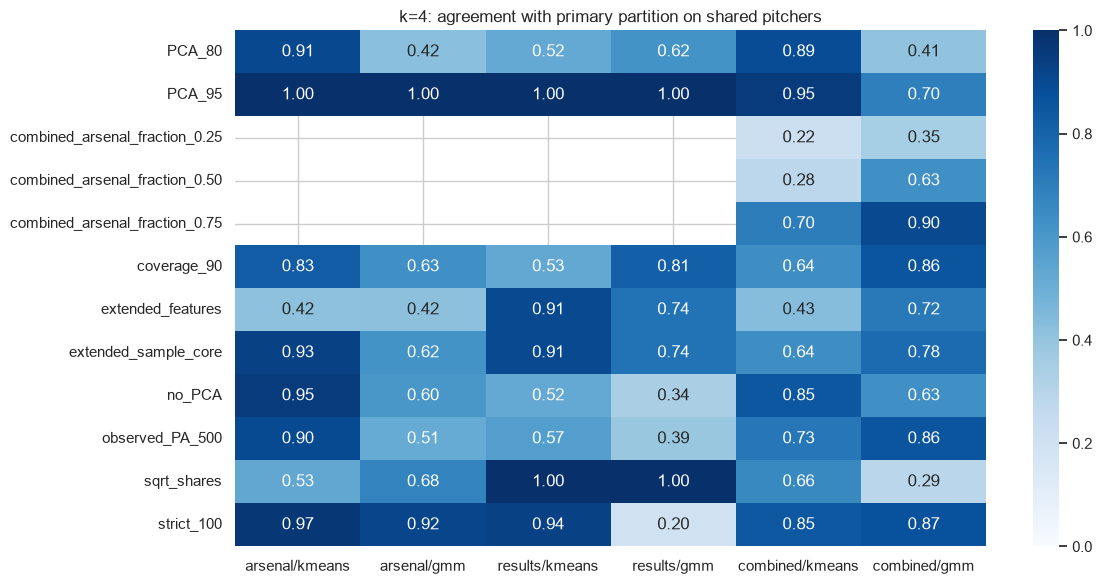

In [7]:
full=pd.read_csv(DATA/'pitcher_features.csv')
finite=np.isfinite(full[COMBINED].to_numpy(float)).all(axis=1)
def coverage_sample(threshold):
    return full.loc[finite & full.analysis_PA_total.ge(100) & full.coverage_PA_fraction.ge(threshold)].sort_values('mlbam_id').reset_index(drop=True)
for threshold,expected in [(.95,df),(1.,strict)]:
    check=coverage_sample(threshold)
    assert check.mlbam_id.tolist()==expected.mlbam_id.tolist()
    np.testing.assert_allclose(check[COMBINED],expected[COMBINED],rtol=1e-10,atol=1e-10)

settings=[('coverage_90',coverage_sample(.9),{},None),
          ('strict_100',strict,{},None),
          ('PCA_80',df,dict(variance=.80),None),
          ('PCA_95',df,dict(variance=.95),None),
          ('no_PCA',df,dict(variance=None),None),
          ('sqrt_shares',df,dict(sqrt_usage=True),None),
          ('observed_PA_500',df.loc[df.analysis_PA_total.ge(500)].reset_index(drop=True),{},None),
          ('extended_sample_core',extended,{},None),
          ('extended_features',extended,{},dict(arsenal=config['extended_arsenal'],results=RESULTS,
                                               combined=config['extended_arsenal']+RESULTS))]
sensitivity_rows=[];sensitivity_agreement=[];sensitivity_labels={}
baseline_id=pd.Index(df.mlbam_id)
def evaluate_setting(setting,frame,options,features=None,only_combined=False):
    feature_map=FEATURE_SETS if features is None else features
    setting_labels={}
    for name,cols in feature_map.items():
        rep=representation(frame,cols,**options)
        for method in ['kmeans','gmm']:
            if only_combined and name!='combined':
                lab=labels[name,method,DETAIL_K]
            else:
                m=fit_model(rep['Z'],method,DETAIL_K)
                lab=m.predict(rep['Z'])
            setting_labels[name,method]=lab
            base_pos=baseline_id.get_indexer(frame.mlbam_id)
            overlap=base_pos>=0
            score=adjusted_rand_score(labels[name,method,DETAIL_K][base_pos[overlap]],lab[overlap])
            sensitivity_rows.append(dict(setting=setting,representation=name,method=method,n=len(frame),
                overlap_n=int(overlap.sum()),dimensions=rep['Z'].shape[1],ari_to_primary=score,
                min_cluster_n=int(np.bincount(lab,minlength=DETAIL_K).min())))
            sensitivity_labels[setting,name,method]=pd.Series(lab,index=frame.mlbam_id)
    for method in ['kmeans','gmm']:
        for a,b in combinations(feature_map,2):
            sensitivity_agreement.append(dict(setting=setting,comparison='representation',method=method,
                pair=f'{a} vs {b}',ari=adjusted_rand_score(setting_labels[a,method],setting_labels[b,method])))
    for name in feature_map:
        sensitivity_agreement.append(dict(setting=setting,comparison='method',method='kmeans vs gmm',pair=name,
            ari=adjusted_rand_score(setting_labels[name,'kmeans'],setting_labels[name,'gmm'])))

for setting,frame,options,features in settings:
    evaluate_setting(setting,frame,options,features)
    print('Sensitivity:',setting,'n=',len(frame),flush=True)
for fraction in [.25,.5,.75]:
    # Weighting applies only to combined; the two single-block baselines are reused.
    setting=f'combined_arsenal_fraction_{fraction:.2f}'
    temp={}
    for name in FEATURE_SETS:
        if name=='combined':
            r=representation(df,COMBINED,arsenal_fraction=fraction)
            for method in ['kmeans','gmm']:
                m=fit_model(r['Z'],method,DETAIL_K);lab=m.predict(r['Z'])
                temp[name,method]=lab
                sensitivity_rows.append(dict(setting=setting,representation=name,method=method,n=len(df),
                    overlap_n=len(df),dimensions=r['Z'].shape[1],
                    ari_to_primary=adjusted_rand_score(labels[name,method,DETAIL_K],lab),
                    min_cluster_n=int(np.bincount(lab,minlength=DETAIL_K).min())))
                sensitivity_labels[setting,name,method]=pd.Series(lab,index=df.mlbam_id)
        else:
            for method in ['kmeans','gmm']:temp[name,method]=labels[name,method,DETAIL_K]
    for method in ['kmeans','gmm']:
        for a,b in combinations(FEATURE_SETS,2):
            sensitivity_agreement.append(dict(setting=setting,comparison='representation',method=method,
                pair=f'{a} vs {b}',ari=adjusted_rand_score(temp[a,method],temp[b,method])))
    sensitivity_agreement.append(dict(setting=setting,comparison='method',method='kmeans vs gmm',pair='combined',
        ari=adjusted_rand_score(temp['combined','kmeans'],temp['combined','gmm'])))
sensitivity=pd.DataFrame(sensitivity_rows);sens_agreement=pd.DataFrame(sensitivity_agreement)
sensitivity.to_csv(OUT/'sensitivity_to_primary.csv',index=False)
sens_agreement.to_csv(OUT/'sensitivity_within_setting_agreement.csv',index=False)
table(sensitivity,'sensitivity_summary')
table(sens_agreement.query('pair == "arsenal vs results"').reset_index(drop=True),'sensitivity_arsenal_results')

extended_control=[]
for name in ['arsenal','combined']:
    for method in ['kmeans','gmm']:
        a=sensitivity_labels['extended_sample_core',name,method]
        b=sensitivity_labels['extended_features',name,method]
        assert a.index.equals(b.index)
        extended_control.append(dict(representation=name,method=method,n=len(a),
            ari_core_vs_extended_same_sample=adjusted_rand_score(a,b)))
table(pd.DataFrame(extended_control),'extended_same_sample_comparison')
primary_overlap=df.set_index('mlbam_id').loc[extended.mlbam_id,COMBINED].to_numpy()
print('Max absolute core/extended baseline-feature difference on shared IDs:',
      np.max(np.abs(primary_overlap-extended[COMBINED].to_numpy())))
fig,ax=plt.subplots(figsize=(12,6))
wide=sensitivity.pivot(index='setting',columns=['representation','method'],values='ari_to_primary')
wide.columns=[f'{a}/{b}' for a,b in wide.columns]
sns.heatmap(wide,annot=True,fmt='.2f',vmin=0,vmax=1,cmap='Blues',ax=ax)
ax.set(title='k=4: agreement with primary partition on shared pitchers',xlabel='',ylabel='')
plt.tight_layout();savefig('08_sensitivity_to_primary')


## 8. t-SNE display 

This plot is not used to choose k or validate clusters. Nonlinear embedding changes distances and apparent gaps; different perplexities/seeds can look different. Crucially, `tsne_embeddings` is separate from the PCA-coordinate dictionary `Zs`; this fixes the original notebook's overwrite bug.


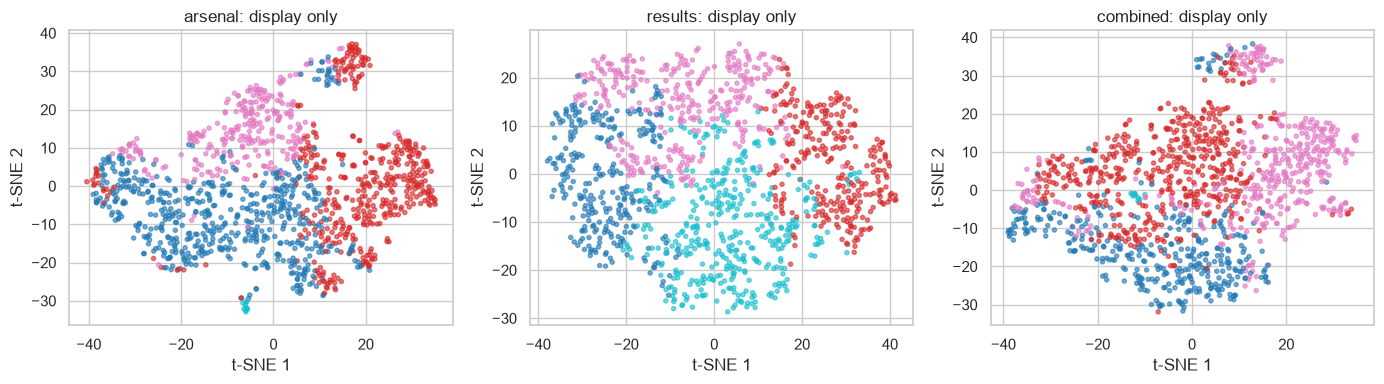

In [8]:
RUN_TSNE=True
tsne_embeddings={}
if RUN_TSNE:
    from sklearn.manifold import TSNE
    fig,axes=plt.subplots(1,3,figsize=(14,4))
    for ax,(name,Z) in zip(axes,Zs.items()):
        embedding=TSNE(n_components=2,perplexity=40,init='pca',learning_rate='auto',
                       random_state=SEED,max_iter=1000).fit_transform(Z)
        tsne_embeddings[name]=embedding
        ax.scatter(*embedding.T,c=labels[name,'kmeans',DETAIL_K],s=9,alpha=.6,cmap='tab10')
        ax.set(title=f'{name}: display only',xlabel='t-SNE 1',ylabel='t-SNE 2')
    plt.tight_layout();savefig('optional_tsne')
else:
    print('t-SNE skipped; no t-SNE evidence enters the findings.')
assert set(Zs)==set(FEATURE_SETS)


## 9. Evidence summary, limits, and reproducibility

The following statements are generated from this execution. **An empirical proposal claim must follow these results**, including any counterexamples, rather than assume that representation always matters more than method. Low agreement can be scientifically useful without establishing independence. Low silhouettes or endpoint BIC optima argue for caution about a unique taxonomy; neither proves a continuum. No null-model test for discrete structure is performed here.

Limits: unequal pitcher precision, selection by coverage/contact eligibility, approximation in PA weights, correlated outcomes, rare pitch shares, compositional geometry, pooling across eras/roles and pitch-classification changes, full-covariance GMM misspecification, a bounded k sweep, and finite optimization budgets. Posterior uncertainty is model conditional. Stability and original-unit interpretation are necessary checks, not independent validation. The sensitivities are targeted, not exhaustive, and are mainly at k=4. No causal, career-prediction, or external generalization claim is supported.

The proposal can organize its argument as: question and definitions; frozen sample and explicit metric; PCA and count ambiguity; matched-k representation/method agreement; perturbation checks; profiles and limitations. Refer to the numbered figures and exported CSVs rather than treating a projection as proof. Full collection/audit evidence remains in the unmodified archive.


In [9]:
lines=['# Measured analysis findings', '',
       '**Supported argument:** Arsenal and results define substantially different pitcher partitions across the tested cluster counts and targeted sensitivities. Exact memberships, especially combined and GMM partitions, depend on analytical choices; these results support representation-dependent descriptions rather than a unique taxonomy.',
       '',f'Frozen build: {source_manifest["build_tag"]}; n={len(df)}.',
       'All results below use real data; no simulated controls were run.','']
for r in selection.itertuples():
    lines.append(f'- {r.representation}/{r.method}: diagnostic {r.criterion} selects k={r.k}, '
                 f'minimum hard cluster n={r.min_cluster_n}; range-boundary selection={r.boundary}.')
lines += ['','## Matched-count agreement']
for method in ['kmeans','gmm']:
    t=agreement.query('pair == "arsenal vs results" and method == @method')
    at4=float(t.loc[t.k.eq(DETAIL_K),'ari'].iloc[0])
    lines.append(f'- {method}, arsenal vs results: ARI {at4:.3f} at k=4; '
                 f'range {t.ari.min():.3f}–{t.ari.max():.3f} over k=2–12.')
for r in agreement.query('k == @DETAIL_K and comparison == "method"').itertuples():
    lines.append(f'- {r.pair}, k-means vs GMM at k=4: ARI {r.ari:.3f}.')
lines.append(f'- Mean within-representation method ARI exceeds mean arsenal/results ARI at '
             f'{int(gaps.gap.gt(0).sum())}/{len(gaps)} tested matched counts; '
             f'the gap ranges {gaps.gap.min():.3f}–{gaps.gap.max():.3f}. This is a descriptive contrast.')
lines += ['','## Perturbation stability at k=4']
for r in stability_summary.query('k == @DETAIL_K').itertuples():
    lines.append(f'- {r.representation}/{r.method}: mean ARI {r.mean:.3f}; '
                 f'empirical 10th–90th percentiles {r.p10:.3f}–{r.p90:.3f} (not a confidence interval).')
lines += ['','## Targeted sensitivity at k=4']
for setting in ['strict_100','no_PCA','observed_PA_500','sqrt_shares']:
    t=sens_agreement.query('setting == @setting and pair == "arsenal vs results"')
    lines.append('- '+setting+': '+', '.join(f'{r.method} arsenal/results ARI={r.ari:.3f}' for r in t.itertuples())+'.')
for r in sensitivity.query('setting == "combined_arsenal_fraction_0.50"').itertuples():
    lines.append(f'- Equal-block combined/{r.method}: ARI to baseline combined={r.ari_to_primary:.3f}.')
lines += ['','## Concrete profiles and analytical qualifications']
for r in representatives.query('representation == "arsenal" and method == "kmeans"').itertuples():
    p=profiles.query('representation == "arsenal" and method == "kmeans" and cluster == @r.cluster')
    means=p.set_index('feature')['mean']
    lines.append(f'- Arsenal k-means cluster {r.cluster} (n={r.n}; representative {r.representative}): '
        f'FF share {means["usage_FF"]:.1%}, SI share {means["usage_SI"]:.1%}, '
        f'other share {means["usage_other"]:.1%}, velocity {means["velo_avg"]:.1f} mph. '
        'These are pitcher means; labels carry no rank.')
lines.append('- A small group dominated by the aggregated other-pitch category is a metric-sensitive result, not a single coherent pitch family. Inspect the share-transform sensitivity before naming it an archetype.')
cross_effects=[]
for method in ['kmeans','gmm']:
    value=eta.query('representation == "arsenal" and method == @method and block == "results"').eta_squared.mean()
    cross_effects.append(f'{method}: {value:.1%}')
lines.append('- At k=4, descriptive mean results-block variance accounted for by arsenal clusters is '
    + ', '.join(cross_effects) + '. This cross-block description is not an out-of-sample estimate.')
lines.append('- Initialization sensitivity uses the full baseline optimization budgets; see initialization_summary.csv and objective differences in initialization_replicates.csv. Successful convergence does not guarantee a global optimum.')
lines += ['','## Interpretation guardrails',
          '- These partitions describe different similarity metrics; no unique natural cluster count is established.',
          '- Stability is algorithmic reproducibility on this sample, not proof of discrete biological types.',
          '- Profiles are circular descriptions; cross-block variance accounting is descriptive, not prediction.',
          '- Sensitivity and method counterexamples must accompany any headline claim.']
findings='\n'.join(lines)+'\n'
(OUT/'measured_findings.md').write_text(findings)
display(Markdown(findings))

assignments=df[['mlbam_id','name']].copy()
for (name,method,k),lab in labels.items():
    assignments[f'{name}_{method}_k{k}']=lab
assignments.to_csv(OUT/'pitcher_cluster_assignments.csv',index=False)
fit_diagnostics=pd.DataFrame(fit_records)
fit_diagnostics.to_csv(OUT/'all_fit_diagnostics.csv',index=False)
assert fit_diagnostics.converged.all(), 'Inspect nonconverged fits before using results'
assert len(assignments)==1305 and assignments.mlbam_id.is_unique
for name in FEATURE_SETS:
    np.testing.assert_allclose(transform(reps[name],df),Zs[name],atol=1e-10)
joblib.dump(dict(representations=reps,models=models,features=FEATURE_SETS,seed=SEED),OUT/'fitted_models.joblib')
input_files=['pitcher_features_core_complete.csv','pitcher_features_strict_complete.csv',
             'pitcher_features_extended_complete.csv','pitcher_features.csv',
             'pitcher_statcast_seasons.csv','pitcher_feature_sets.json','run_manifest.json']
versions=dict(python=platform.python_version(),numpy=np.__version__,pandas=pd.__version__,
              scipy=scipy.__version__,sklearn=sklearn.__version__,seaborn=sns.__version__,
              matplotlib=__import__('matplotlib').__version__,joblib=joblib.__version__)
manifest=dict(source_build=source_manifest['build_tag'],seed=SEED,versions=versions,
    n_primary=len(df),feature_sets=FEATURE_SETS,k_range=K_RANGE,detail_k=DETAIL_K,
    stability_k=STABILITY_K,stability_pairs=N_STABILITY,pca_variance=.9,
    baseline_kmeans_starts=30,baseline_gmm_starts=20,resampling_kmeans_starts=10,
    resampling_gmm_starts=5,gmm_reg_covar=1e-4,nonconverged_fits=int((~fit_diagnostics.converged).sum()),
    total_fits=len(fit_diagnostics),
    input_sha256={f:hashlib.sha256((DATA/f).read_bytes()).hexdigest() for f in input_files})
(OUT/'analysis_manifest.json').write_text(json.dumps(manifest,indent=2))
print('All fits converged:',len(fit_diagnostics),'fits. Saved tables, figures, assignments and model objects.')
print('Package versions:',versions)


# Measured analysis findings

**Supported argument:** Arsenal and results define substantially different pitcher partitions across the tested cluster counts and targeted sensitivities. Exact memberships, especially combined and GMM partitions, depend on analytical choices; these results support representation-dependent descriptions rather than a unique taxonomy.

Frozen build: regular-season-coverage95-2026-11-22; n=1305.
All results below use real data; no simulated controls were run.

- arsenal/kmeans: diagnostic silhouette selects k=8, minimum hard cluster n=10; range-boundary selection=False.
- arsenal/gmm: diagnostic bic selects k=9, minimum hard cluster n=11; range-boundary selection=False.
- results/kmeans: diagnostic silhouette selects k=2, minimum hard cluster n=616; range-boundary selection=True.
- results/gmm: diagnostic bic selects k=2, minimum hard cluster n=376; range-boundary selection=False.
- combined/kmeans: diagnostic silhouette selects k=6, minimum hard cluster n=10; range-boundary selection=False.
- combined/gmm: diagnostic bic selects k=6, minimum hard cluster n=37; range-boundary selection=False.

## Matched-count agreement
- kmeans, arsenal vs results: ARI 0.037 at k=4; range 0.000–0.037 over k=2–12.
- gmm, arsenal vs results: ARI 0.001 at k=4; range -0.005–0.010 over k=2–12.
- arsenal, k-means vs GMM at k=4: ARI 0.078.
- results, k-means vs GMM at k=4: ARI 0.233.
- combined, k-means vs GMM at k=4: ARI 0.042.
- Mean within-representation method ARI exceeds mean arsenal/results ARI at 11/11 tested matched counts; the gap ranges 0.023–0.240. This is a descriptive contrast.

## Perturbation stability at k=4
- arsenal/gmm: mean ARI 0.740; empirical 10th–90th percentiles 0.583–0.957 (not a confidence interval).
- arsenal/kmeans: mean ARI 0.607; empirical 10th–90th percentiles 0.414–0.812 (not a confidence interval).
- combined/gmm: mean ARI 0.693; empirical 10th–90th percentiles 0.538–0.838 (not a confidence interval).
- combined/kmeans: mean ARI 0.691; empirical 10th–90th percentiles 0.567–0.851 (not a confidence interval).
- results/gmm: mean ARI 0.482; empirical 10th–90th percentiles 0.283–0.726 (not a confidence interval).
- results/kmeans: mean ARI 0.518; empirical 10th–90th percentiles 0.356–0.844 (not a confidence interval).

## Targeted sensitivity at k=4
- strict_100: kmeans arsenal/results ARI=0.036, gmm arsenal/results ARI=0.007.
- no_PCA: kmeans arsenal/results ARI=0.032, gmm arsenal/results ARI=0.010.
- observed_PA_500: kmeans arsenal/results ARI=0.050, gmm arsenal/results ARI=0.012.
- sqrt_shares: kmeans arsenal/results ARI=0.028, gmm arsenal/results ARI=-0.000.
- Equal-block combined/kmeans: ARI to baseline combined=0.281.
- Equal-block combined/gmm: ARI to baseline combined=0.631.

## Concrete profiles and analytical qualifications
- Arsenal k-means cluster 0 (n=574; representative DL Hall): FF share 33.5%, SI share 12.8%, other share 0.1%, velocity 88.0 mph. These are pitcher means; labels carry no rank.
- Arsenal k-means cluster 1 (n=452; representative Jon Gray): FF share 49.6%, SI share 4.7%, other share 0.0%, velocity 90.3 mph. These are pitcher means; labels carry no rank.
- Arsenal k-means cluster 2 (n=269; representative Dario Agrazal): FF share 11.9%, SI share 43.8%, other share 0.0%, velocity 89.3 mph. These are pitcher means; labels carry no rank.
- Arsenal k-means cluster 3 (n=10; representative Mitch Bratt): FF share 38.0%, SI share 12.9%, other share 22.7%, velocity 88.6 mph. These are pitcher means; labels carry no rank.
- A small group dominated by the aggregated other-pitch category is a metric-sensitive result, not a single coherent pitch family. Inspect the share-transform sensitivity before naming it an archetype.
- At k=4, descriptive mean results-block variance accounted for by arsenal clusters is kmeans: 5.3%, gmm: 1.0%. This cross-block description is not an out-of-sample estimate.
- Initialization sensitivity uses the full baseline optimization budgets; see initialization_summary.csv and objective differences in initialization_replicates.csv. Successful convergence does not guarantee a global optimum.

## Interpretation guardrails
- These partitions describe different similarity metrics; no unique natural cluster count is established.
- Stability is algorithmic reproducibility on this sample, not proof of discrete biological types.
- Profiles are circular descriptions; cross-block variance accounting is descriptive, not prediction.
- Sensitivity and method counterexamples must accompany any headline claim.


All fits converged: 909 fits. Saved tables, figures, assignments and model objects.
Package versions: {'python': '3.11.5', 'numpy': '2.4.6', 'pandas': '3.1.1', 'scipy': '1.17.1', 'sklearn': '1.9.1', 'seaborn': '0.13.2', 'matplotlib': '3.11.2', 'joblib': '1.6.0'}


## Sources and methods references

Data snapshot: supplied `pitcher_data.zip`, built November 22, 2026; `run_manifest.json`, `pitcher_feature_sets.json`, `feature_dictionary.csv`, and `audit/` are the authoritative local provenance. Retrieved source documentation November 22, 2026:

* [Baseball Savant pitch arsenals](https://baseballsavant.mlb.com/leaderboard/pitch-arsenals), [expected statistics](https://baseballsavant.mlb.com/leaderboard/expected_statistics), [exit velocity/barrels](https://baseballsavant.mlb.com/leaderboard/statcast), and [Baseball Reference](https://www.baseball-reference.com/). These are upstream data sources, not independent validation samples.
* [pybaseball repository and source documentation](https://github.com/jldbc/pybaseball), version 2.2.7 in the collection manifest.
* [MLB xwOBA glossary](https://www.mlb.com/glossary/statcast/expected-woba) and [barrel glossary](https://www.mlb.com/glossary/statcast/barrel).
* [scikit-learn 1.8 clustering guide](https://scikit-learn.org/1.8/modules/clustering.html): k-means, silhouette, ARI and internal-score assumptions. See also Lloyd (1982), *Least Squares Quantization in PCM*, IEEE Transactions on Information Theory 28:129–137; Rousseeuw (1987), *Silhouettes*, Journal of Computational and Applied Mathematics 20:53–65; Hubert & Arabie (1985), *Comparing Partitions*, Journal of Classification 2:193–218.
* [scikit-learn 1.8 mixture guide](https://scikit-learn.org/1.8/modules/mixture.html): EM, covariance models, and BIC. See Dempster, Laird & Rubin (1977), *Maximum Likelihood from Incomplete Data via the EM Algorithm*, JRSS B 39:1–38; Schwarz (1978), *Estimating the Dimension of a Model*, Annals of Statistics 6:461–464. Gaussian mixtures are flexible density models and should not automatically be read as distinct populations.
* [scikit-learn 1.8 PCA documentation](https://scikit-learn.org/1.8/modules/decomposition.html#pca). Components preserve variance, not necessarily cluster-relevant information.

Reproduce with Python and the versions in `outputs/analysis_manifest.json`. Run all notebook cells in order with the frozen dataset at `data/pitcher_data/` or `PITCHER_DATA_DIR` set to its directory. Alternatively, `python run_notebook.py` executes the exact notebook cells, captures tables/figures, and saves the executed notebook without requiring Jupyter. `fitted_models.joblib` is a convenience for this trusted local run; the notebook and CSVs are the portable reproducibility record. Do not load untrusted pickle/joblib files.
